## Workshop 3: Segmentación de clientes con Clustering (K-Means vs. Agglomerative vs. DBSCAN)

In [422]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("./data/Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [423]:
df.shape

(200, 5)

In [424]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [425]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [426]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [427]:
df.drop(columns=["CustomerID"], inplace=True)
#2.2

In [428]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  200 non-null    object
 1   Age                     200 non-null    int64 
 2   Annual Income (k$)      200 non-null    int64 
 3   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 6.4+ KB


Otro

In [429]:
#2.3
# Codificación One-Hot de Gender (drop='first' deja solo Gender_Male)
encoder = OneHotEncoder(drop='first', sparse_output=False)
encoded_array = encoder.fit_transform(df[['Gender']])

df_encoded = pd.DataFrame(
    encoded_array,
    columns=encoder.get_feature_names_out(['Gender']),
    dtype=int,
    index=df.index,
)

# Reemplazamos la columna original por la codificada
df = pd.concat([df.drop(columns=['Gender']), df_encoded], axis=1)

In [430]:
df.head()

,Age,Annual Income (k$),Spending Score (1-100),Gender_Male
0,19,15,39,1
1,21,15,81,1
2,20,16,6,0
3,23,16,77,0
4,31,17,40,0


In [431]:
features = ["Gender_Male", "Age", "Annual Income (k$)", "Spending Score (1-100)"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

Fase 3

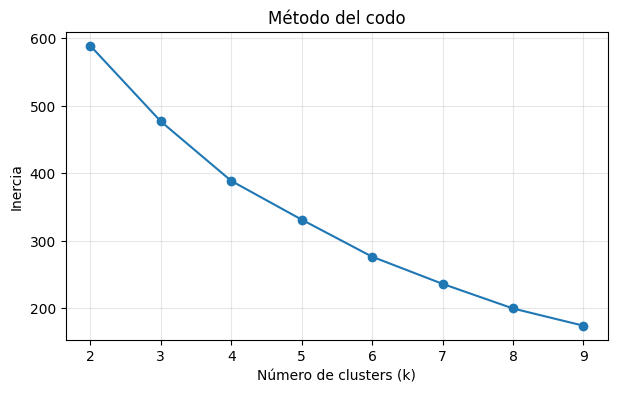

In [432]:
import matplotlib.pyplot as plt

inertias = []
ks = range(2, 10)

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

In [433]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)


results = []

for k, inertia in zip(ks, inertias):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    results.append({
        "k": k,
        "Inercia": inertia,
        "Silhouette Score": silhouette_score(X_scaled, labels_k),
    })

df_kmeans = pd.DataFrame(results).set_index("k")
df_kmeans.round(4)


,Inercia,Silhouette Score
k,,
2,588.8027,0.2518
3,476.7876,0.2595
4,388.7179,0.2984
5,331.3099,0.3041
6,276.4118,0.3311
7,236.2049,0.3574
8,199.7505,0.3880
9,174.2355,0.4031


In [434]:
# K-Means

k=4
model = KMeans(
    n_clusters=k,     
    random_state=42,
    n_init=10
)

labels = model.fit_predict(X_scaled)

Fase 4

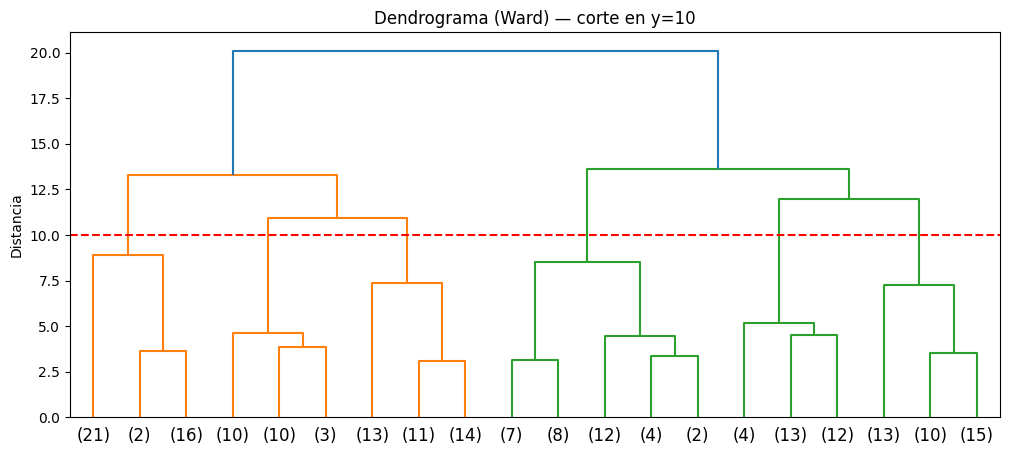

In [435]:
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20)   # solo las 20 ramas de arriba, se lee mejor
plt.axhline(y=10, color="red", linestyle="--")  # el corte
plt.title("Dendrograma (Ward) — corte en y=10")
plt.ylabel("Distancia")
plt.show()

In [436]:
from sklearn.metrics import silhouette_score

# Silhouette para k = 2..8
rows = []
for k in range(2, 9):
    agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels_k = agg.fit_predict(X_scaled)
    rows.append({"k": k, "Silhouette Score": silhouette_score(X_scaled, labels_k)})

agg_results = pd.DataFrame(rows)
agg_results

,k,Silhouette Score
0,2,0.241780
1,3,0.248345
2,4,0.263226
3,5,0.286994
4,6,0.310245
5,7,0.345558
6,8,0.378880


In [437]:
best_k_agg = 6
agg_model = AgglomerativeClustering(n_clusters=best_k_agg, linkage="ward")
labels_agglomerative = agg_model.fit_predict(X_scaled)

print("Silhouette:", silhouette_score(X_scaled, labels_agglomerative))

Silhouette: 0.3102445968526053


In [438]:
# Etiquetas a partir del corte (por altura o por número de grupos)
labels_dendro = fcluster(Z, t=10, criterion="distance")   # o: fcluster(Z, 6, criterion="maxclust")
pd.Series(labels_dendro).value_counts()

1    39
6    38
3    38
4    33
5    29
2    23
Name: count, dtype: int64

### Preguntas — Agglomerative

**¿Cuántos grupos sugiere el dendrograma?**
6 grupos. Entre las distancias 8.9 y 10.9 no hay ninguna unión, así que al cortar en 10 la línea cruza 6 ramas. Es el espacio vacío más grande después del de k = 2, y 2 grupos es muy poco para segmentar clientes.

**¿Coincide con el mejor k según Silhouette?**
No del todo. El Silhouette sube sin parar (0.24 con k = 2, 0.31 con k = 6, 0.38 con k = 8), sin un pico claro: k = 8 sale "mejor" solo porque es el último valor probado. Elegimos **k = 6** porque es el corte que el dendrograma muestra claramente y el Silhouette ya es razonable, sin dividir a los clientes en grupos demasiado pequeños.

Fase 5

In [439]:
from itertools import product
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.3, 0.5, 0.7, 0.9, 1.1]
min_samples_values = [3, 5, 8, 10]

results = []

for eps, min_samples in product(eps_values, min_samples_values):
    labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)

    mask = labels_db != -1
    n_clusters = len(set(labels_db[mask]))
    n_noise = (~mask).sum()

    score = silhouette_score(X_scaled[mask], labels_db[mask]) if n_clusters >= 2 else None

    results.append({
        "eps": eps,
        "min_samples": min_samples,
        "N° clusters": n_clusters,
        "N° ruido": n_noise,
        "Silhouette Score": score,
    })

df_dbscan = pd.DataFrame(results)
df_dbscan.round(4)

,eps,min_samples,N° clusters,N° ruido,Silhouette Score
0,0.3,3,14,144,0.6293
1,0.3,5,1,194,NaN
2,0.3,8,0,200,NaN
3,0.3,10,0,200,NaN
4,0.5,3,18,49,0.4746
5,0.5,5,9,105,0.5395
6,0.5,8,2,169,0.7089
7,0.5,10,2,178,0.7694
8,0.7,3,9,14,0.1322
9,0.7,5,7,37,0.2766


In [440]:
# Modelo final de DBSCAN con los parámetros elegidos
eps_final, min_samples_final = 0.9, 8
labels_dbscan = DBSCAN(eps=eps_final, min_samples=min_samples_final).fit_predict(X_scaled)
labels_kmeans = labels  # K-Means con el k de la celda de K-Means

print("DBSCAN -> clusters:", len(set(labels_dbscan) - {-1}), "| ruido:", (labels_dbscan == -1).sum())

DBSCAN -> clusters: 4 | ruido: 25


In [441]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada por cada componente:", pca.explained_variance_ratio_)
print("Varianza explicada acumulada:", pca.explained_variance_ratio_.sum())

Varianza explicada por cada componente: [0.33690046 0.26230645 0.23260639]
Varianza explicada acumulada: 0.8318132878845951


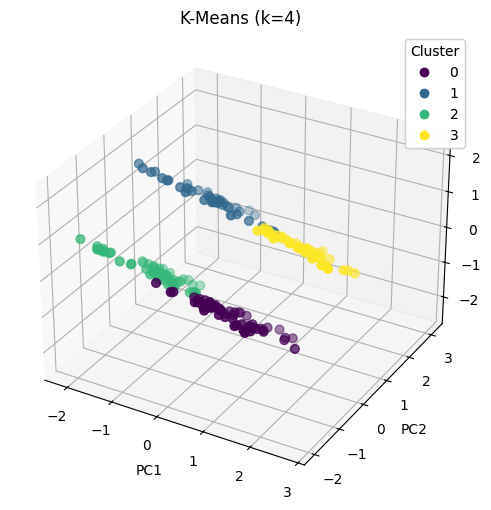

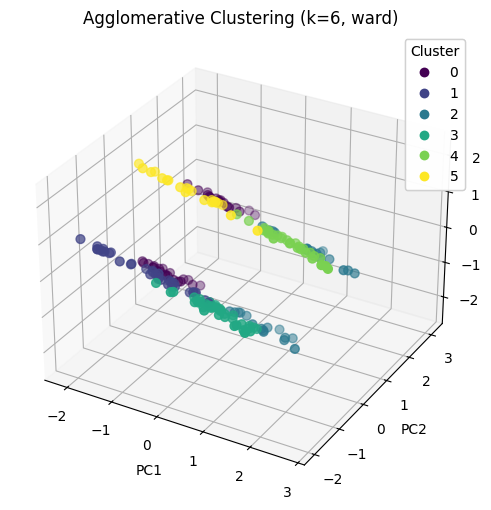

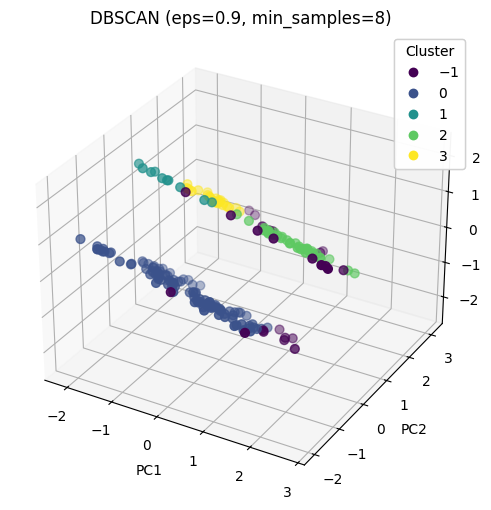

In [442]:
def plot_clusters_3d(X_pca, labels, title):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
        c=labels,
        cmap="viridis",
        s=40
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    ax.set_title(title)

    legend = ax.legend(*scatter.legend_elements(), title="Cluster")
    ax.add_artist(legend)

    plt.show()


k_kmeans = len(set(labels_kmeans))
plot_clusters_3d(X_pca, labels_kmeans, f"K-Means (k={k_kmeans})")
plot_clusters_3d(X_pca, labels_agglomerative, f"Agglomerative Clustering (k={best_k_agg}, ward)")
plot_clusters_3d(X_pca, labels_dbscan, f"DBSCAN (eps={eps_final}, min_samples={min_samples_final})")

In [443]:
mask_db = labels_dbscan != -1
k_kmeans = len(set(labels_kmeans))

comparison = pd.DataFrame([
    {
        "Método": "K-Means",
        "Parámetros": f"k = {k_kmeans}",
        "N° de clusters": k_kmeans,
        "N° de puntos de ruido": "N/A",
        "Silhouette Score": silhouette_score(X_scaled, labels_kmeans),
    },
    {
        "Método": "Agglomerative",
        "Parámetros": f'k = {best_k_agg}, linkage="ward"',
        "N° de clusters": len(set(labels_agglomerative)),
        "N° de puntos de ruido": "N/A",
        "Silhouette Score": silhouette_score(X_scaled, labels_agglomerative),
    },
    {
        "Método": "DBSCAN",
        "Parámetros": f"eps = {eps_final}, min_samples = {min_samples_final}",
        "N° de clusters": len(set(labels_dbscan[mask_db])),
        "N° de puntos de ruido": int((~mask_db).sum()),
        # El ruido se excluye del cálculo
        "Silhouette Score": silhouette_score(X_scaled[mask_db], labels_dbscan[mask_db]),
    },
]).set_index("Método")

comparison.round(4)

,Parámetros,N° de clusters,N° de puntos de ruido,Silhouette Score
Método,,,,
K-Means,k = 4,4,N/A,0.2984
Agglomerative,"k = 6, linkage=""ward""",6,N/A,0.3102
DBSCAN,"eps = 0.9, min_samples = 8",4,25,0.2685


## Fase 6: ¿Cuáles son las clases naturales?

**Conclusión: consideramos que existen 4 grupos y que K-Means es el método más adecuado para definirlos.**

### Por qué K-Means

A igual número de clusters, K-Means obtiene un Silhouette mayor que Agglomerative:

| k | K-Means | Agglomerative (ward) |
|---:|---:|---:|
| 4 | 0.2984 | 0.2632 |
| 6 | 0.3311 | 0.3102 |

También supera a DBSCAN (0.2685 con eps = 0.9 y min_samples = 8), que además deja 25 clientes como ruido. Ese Silhouette de DBSCAN se calcula sin esos puntos, por lo que no es comparable de forma directa.

### Por qué 4 grupos

Con solo 200 clientes, preferimos no sobresegmentar: con más grupos, cada uno queda con pocos clientes y es más difícil de interpretar. Con k = 4, K-Means forma grupos de tamaño equilibrado (entre 42 y 56 clientes).

### Limitaciones

- El Silhouette de 0.30 indica una separación **moderada**: los grupos se distinguen, pero sus fronteras se solapan en parte.
- Las 3 componentes del PCA capturan el 83.2% de la varianza, así que los gráficos 3D conservan la mayor parte de la información, pero no toda.
- Con k = 4, K-Means separa a los clientes sobre todo por género y edad. El ingreso promedio es casi igual en los cuatro grupos (de 58 a 62 k$).

### Alternativa: 6 grupos

Con k = 6 el Silhouette de K-Means sube a 0.3311, y el dendrograma de Agglomerative también sugiere 6 grupos. Con 6 aparecen dos segmentos de ingreso alto (alrededor de 90 k$) que con 4 quedan mezclados: uno con gasto alto y otro con gasto bajo. Si el negocio necesita separar por ingreso y gasto, 6 es una opción válida.